<a href="https://colab.research.google.com/github/deepshikhapandit-ai/OCR-Invoice-Reader/blob/main/Activity_2_(26MSPHR002).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# MOSFET Subthreshold and Inversion Simulation

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


In [ ]:
# 1. Physical constants
q = 1.602e-19
k = 1.381e-23
T = 300
eps0 = 8.854e-12
eps_si = 11.7 * eps0
eps_ox = 3.9 * eps0

In [ ]:
# 2. MOSFET parameters
Na = 1e22                 # Acceptor concentration (m^-3)
ni = 1.45e16             # Intrinsic carrier concentration (m^-3)
tox = 10e-9              # Oxide thickness (m)
W = 10e-6               # Channel width (m)
L = 1e-6                # Channel length (m)
mu = 0.045               # Mobility (m^2/Vs)
Vfb = 0.0                # Flat-band voltage (V)
Vds = 0.1               # Drain-source voltage(V)

In [ ]:
# 3. Derived parameters

Vt = k*T/q
Cox = eps_ox/tox
phi_f = Vt*np.log(Na/ni)
Vth = Vfb + 2*phi_f + np.sqrt(4*q*eps_si*Na*phi_f)/Cox

print("Thermal voltage =", Vt, "V")
print("Threshold voltage =", Vth, "V")

Thermal voltage = 0.025861423220973782 V
Threshold voltage = 0.8344855664904437 V


In [ ]:
# 4. Gate voltage range
Vgs = np.linspace(0, 1.5, 300)

In [ ]:
# 5. Calculate surface potential
def surface_potential(Vg):
    psi_max = 2*phi_f

    def equation(psi):
        Qdep = np.sqrt(2*q*eps_si*Na*psi)
        return Vfb + psi + Qdep/Cox - Vg

    if Vg <= Vfb:
        return 0.0

    if equation(psi_max) < 0:
        return psi_max

    return brentq(equation, 0, psi_max)

psi_s = np.array([surface_potential(v) for v in Vgs])

In [ ]:
# 6. Calculate drain current
n_factor = 1.5
I0 = 1e-12

Id = np.zeros_like(Vgs)

for i, vg in enumerate(Vgs):

    if vg < Vth:
        # Subthreshold region
        Id[i] = I0*np.exp((vg-Vth)/(n_factor*Vt)) * \
                 (1-np.exp(-Vds/Vt))

    else:
        # Strong inversion region (Square-law model)
        Id[i] = 0.5*mu*Cox*(W/L)*(vg-Vth)**2


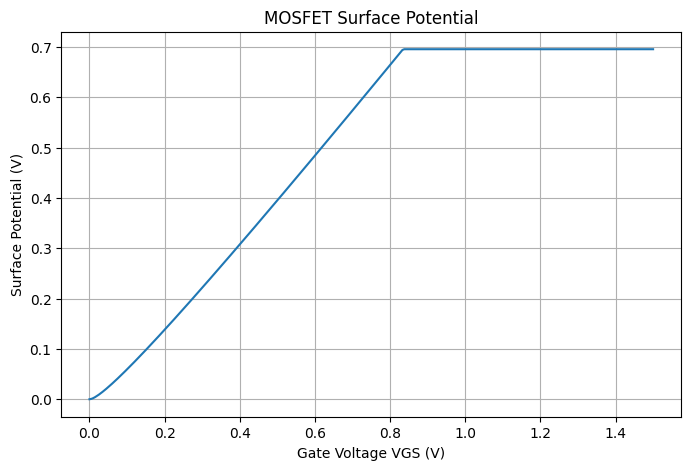

In [ ]:
# 7. Plot Surface Potential
plt.figure(figsize=(8,5))
plt.plot(Vgs, psi_s)
plt.xlabel("Gate Voltage VGS (V)")
plt.ylabel("Surface Potential (V)")
plt.title("MOSFET Surface Potential")
plt.grid(True)
plt.show()

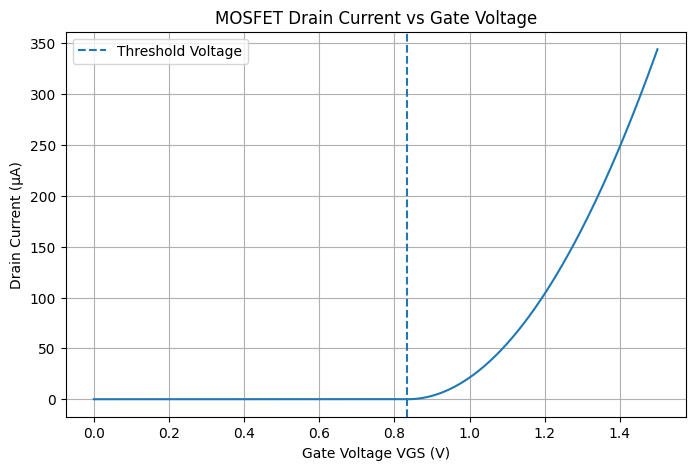

In [ ]:
# 8. Plot Drain Current - Linear scale
plt.figure(figsize=(8,5))
plt.plot(Vgs, Id*1e6)
plt.axvline(Vth, linestyle="--", label="Threshold Voltage")
plt.xlabel("Gate Voltage VGS (V)")
plt.ylabel("Drain Current (µA)")
plt.title("MOSFET Drain Current vs Gate Voltage")
plt.grid(True)
plt.legend()
plt.show()


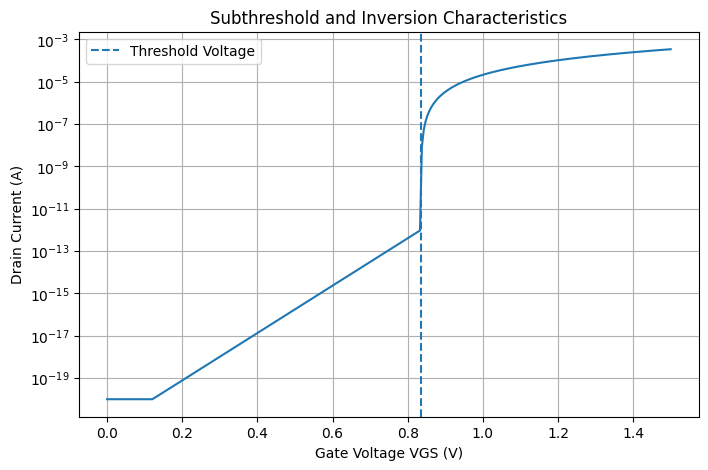

In [ ]:
# 9. Plot Drain Current - Logarithmic scale
plt.figure(figsize=(8,5))
plt.semilogy(Vgs, np.maximum(Id, 1e-20))
plt.axvline(Vth, linestyle="--", label="Threshold Voltage")
plt.xlabel("Gate Voltage VGS (V)")
plt.ylabel("Drain Current (A)")
plt.title("Subthreshold and Inversion Characteristics")
plt.grid(True, which="both")
plt.legend()
plt.show()

In [ ]:
# 10. Print results
print("Maximum Drain Current =", np.max(Id), "A")
print("Simulation completed successfully!")

Maximum Drain Current = 0.0003441134124279526 A
Simulation completed successfully!
